# FlameGPU development

In [1]:
# check if pyflamegpu is installed and if not install it
import importlib.util
if importlib.util.find_spec('pyflamegpu') is None:
    import sys
    !{sys.executable} -m pip install --extra-index-url https://whl.flamegpu.com/whl/cuda130/ pyflamegpu

# Import pyflamegpu and some other libraries we will use in the tutorial
import pyflamegpu
import pyflamegpu.codegen
import sys, random, math
import numpy as np
import matplotlib.pyplot as plt
import importlib

#set matplotlib backend to widget for some advanced plotting tools
%matplotlib widget

# import
import visualiser

# reload local modules
importlib.reload(visualiser)

<module 'visualiser' from 'c:\\Users\\yhmg1v\\OneDrive - Personal\\OneDrive\\Google Drive\\10 Coding Models\\04 Housing UBDC\\FlameGPU\\visualiser.py'>

## Model parameters

In [2]:
# Model Parameters
DIM = 64                # Dimensions of our 2D grid
SIMULATION_STEPS = 150  # Number of time steps
DENSITY = 0.8           # Density of houses
OCCUPANCY = 0.8         # Occupancy rate at initialisation

# Global parameters
INTEREST = 3.7
LTV = 90
CAPITAL_THRESHOLD = 200000

## Create model and agents

Include message dependencies

In [3]:
def create_model():
    model = pyflamegpu.ModelDescription("housing")
    return model

def define_environment(model):
    env = model.Environment()

    # Env properties
    env = model.Environment()
    env.newPropertyFloat("INTEREST", INTEREST)
    env.newPropertyInt("LTV", LTV)
    env.newPropertyInt("CAPITAL_THRESHOLD", CAPITAL_THRESHOLD)

def define_agents(model):
    """
    House agent
    """
    ## House
    h = model.newAgent("house")
    h.newVariableInt("constructed?")
    h.newVariableInt("x")
    h.newVariableInt("y")
    h.newVariableInt("my_owner")    # ID of the household
    h.newVariableInt("price")
    h.newVariableInt("offered_to")  # ID of the household who made an offer
    h.newVariableInt("for-sale?")   # 0 or 1
    h.newVariableInt("for-rent?")   # 0 or 1

    ## Households
    hh = model.newAgent("household")
    hh.newVariableInt("x")
    hh.newVariableInt("y")        
    hh.newVariableInt("income")
    hh.newVariableInt("capital")   
    hh.newVariableInt("my_house")        # ID of the house
    hh.newVariableInt("on_market?")      # 0 or 1, on the mortgage market or not
    hh.newVariableInt("active?")         # True or False

    # Function 1
    hh_market_participation_fn = hh.newRTCFunction(
        "hh_market_participation", pyflamegpu.codegen.translate(hh_market_participation)
    )

    # Function 2
    h_put_on_market_fn = h.newRTCFunction(
        "h_put_on_market", pyflamegpu.codegen.translate(h_put_on_market)
    )
    h_put_on_market_fn.setMessageOutput("h_put_on_market") ## Write the messages!
    h_put_on_market_fn.setMessageOutputOptional(True) ## Means that some houses may send the message and some may not

    # Function 3
    hh_make_offers_fn = hh.newRTCFunction(
        "hh_make_offers", pyflamegpu.codegen.translate(hh_make_offers)
    )
    hh_make_offers_fn.setMessageInput("h_put_on_market")
    hh_make_offers_fn.setMessageOutput("hh_make_offers")
    hh_make_offers_fn.setMessageOutputOptional(True)
    
    # Function 4
    h_recieve_offer_fn = h.newRTCFunction(
    "h_recieve_offer", pyflamegpu.codegen.translate(h_recieve_offer)
    )
    h_recieve_offer_fn.setMessageInput("hh_make_offers") ## Write the messages!
    h_recieve_offer_fn.setMessageOutput("h_recieve_offer") ## Write the messages!
    h_recieve_offer_fn.setMessageOutputOptional(True) ## Means that some houses may send the message and some may not

    # Function 5
    hh_offer_accepted_fn = hh.newRTCFunction(
        "hh_offer_accepted", pyflamegpu.codegen.translate(hh_offer_accepted)
    )
    hh_offer_accepted_fn.setMessageInput("h_recieve_offer") ## Write the messages!
    # hh_offer_accepted_fn.setMessageOutput("hh_offer_accepted") ## Write the messages!
    hh_offer_accepted_fn.setMessageOutputOptional(True) ## Means that some households may send the message and some may not

    # Function 6
    hh_move_fn = hh.newRTCFunction(
        "hh_move", pyflamegpu.codegen.translate(hh_move)
    )
    hh_move_fn.setMessageInput("h_recieve_offer") ## Write the messages!

    
    

    


    




In [4]:
## ----------------------
## Define dependencies
## ----------------------

def define_dependencies(model):
    h = model.Agent("house")
    hh = model.Agent("household")
    hh_market_participation_fn = hh.Function("hh_market_participation")
    h_put_on_market_fn = h.Function("h_put_on_market")
    hh_make_offers_fn = hh.Function("hh_make_offers")
    h_recieve_offer_fn = h.Function("h_recieve_offer")
    hh_offer_accepted_fn = hh.Function("hh_offer_accepted")
    hh_move_fn = hh.Function("hh_move")

    # Define dependencies
    h_put_on_market_fn.dependsOn(hh_market_participation_fn)
    hh_make_offers_fn.dependsOn(h_put_on_market_fn)
    h_recieve_offer_fn.dependsOn(hh_make_offers_fn)
    # h_recieve_offer_fn.dependsOn(h_recieve_offer_fn)
    hh_offer_accepted_fn.dependsOn(h_recieve_offer_fn)
    hh_move_fn.dependsOn(hh_offer_accepted_fn)

    model.addExecutionRoot(hh_market_participation_fn)
    model.generateLayers()


## Define messages

In [5]:
## ------------------
## Define messages
## ------------------

def define_messages(model):

    ## hh_market participation

    ## h_put_on_market
    msg_h_put_on_market = model.newMessageBruteForce("h_put_on_market")
    msg_h_put_on_market.newVariableInt("h_ID")
    msg_h_put_on_market.newVariableInt("h_price")

    ## hh_make_offers
    msg_hh_make_offers = model.newMessageBruteForce("hh_make_offers")
    msg_hh_make_offers.newVariableInt("h_offered")
    msg_hh_make_offers.newVariableInt("h_offered_x")
    msg_hh_make_offers.newVariableInt("h_offered_y")
    msg_hh_make_offers.newVariableInt("hh_offering")

    ## h_recieve_offer
    msg_h_recieve_offer = model.newMessageBruteForce("h_recieve_offer")
    msg_h_recieve_offer.newVariableInt("h_offered_conf")
    msg_h_recieve_offer.newVariableInt("h_offered_conf_x")
    msg_h_recieve_offer.newVariableInt("h_offered_conf_y")
    msg_h_recieve_offer.newVariableInt("hh_offering_conf")

    ## hh_offer_accepted

    ## hh_move
    msg_hh_move = model.newMessageBruteForce("hh_move")

    ## hh_immigration

    ## hh_emigration

    pass




## Define functions

In [6]:
## Part of a submodel
## purchasing_
## ------------------
##  Functions
## ------------------
@pyflamegpu.agent_function
def hh_market_participation(message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageNone):
    """
    Put the household on the housing market if their capital are high
    """
    ## If I have high capital, go on the market
    if pyflamegpu.getVariableInt("capital") > pyflamegpu.environment.getPropertyInt("CAPITAL_THRESHOLD"):
        pyflamegpu.setVariableInt("on_market?", True)
    return pyflamegpu.ALIVE

@pyflamegpu.agent_function
def h_put_on_market(message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageBruteForce):
    """
    If the house is vacant, put it on the market
    """
    if pyflamegpu.getVariableInt("constructed") == True:
        ## If the house is vacant, put it for sale
        if pyflamegpu.getVariableInt("my_owner") == 0:
            pyflamegpu.setVariableInt("for_sale?", True)

            ## Report the house's ID
            # message_out.setIndex(pyflamegpu.getVariableInt("x"), pyflamegpu.getVariableInt("y"))
            message_out.setVariableInt("h_ID", pyflamegpu.getID())
            message_out.setVariableInt("h_x", pyflamegpu.getVariableInt("x"))
            message_out.setVariableInt("h_y", pyflamegpu.getVariableInt("y"))
            message_out.setVariableInt("h_price", pyflamegpu.getVariableInt("price"))
    return pyflamegpu.ALIVE


@pyflamegpu.agent_function
def hh_make_offers(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageBruteForce):
    """
    Make offers on vacant houses within my budget
    """
    current_rand = 0
    h_offered = 0
    h_offered_x = 0
    h_offered_y = 0
    hh_offering = 0
    for message in message_in:
        if message.getVariableInt("h_price") <= pyflamegpu.getVariableInt("capital"):
            ## Toss a die
            new_rand = pyflamegpu.random.uniformFloat()
            ## If the die value is higher than the previous highest value, make an offer on the house
            if current_rand < new_rand:
                h_offered = message.getVariableInt("h_ID")
                h_offered_x = message.getVariableInt("h_x")
                h_offered_y = message.getVariableInt("h_y")
                hh_offering = pyflamegpu.getID()
                pyflamegpu.setVariableInt("active?", True)
                current_rand = new_rand
    ## Send all the messages
    message_out.setVariableInt("h_offered", h_offered)
    message_out.setVariableInt("h_offered_x", h_offered_x)
    message_out.setVariableInt("h_offered_y", h_offered_y)
    message_out.setVariableInt("hh_offering", hh_offering) 
    return pyflamegpu.ALIVE


@pyflamegpu.agent_function
def h_recieve_offer(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageBruteForce):
    """
    Consider offers and send a confirmation for the accepted offer
    """
    if pyflamegpu.getVariableInt("constructed") == True:
        current_rand = 0
        h_offered_conf = 0
        h_offered_conf_x = 0
        h_offered_conf_y = 0
        hh_offering_conf = 0
        for message in message_in:
            ## If I am the house the an offer was made upon
            if message.getVariableInt("h_offered") == pyflamegpu.getID():
                ## Randomly select an offer
                new_rand = pyflamegpu.random.uniformFloat()
                if current_rand < new_rand:
                    h_offered_conf = message.getVariableInt("h_offered")
                    h_offered_conf_x = message.getVariableInt("h_offered_x")
                    h_offered_conf_y = message.getVariableInt("h_offered_y")
                    hh_offering_conf = message.getVariableInt("hh_offering")
                    pyflamegpu.setVariableInt("offered_to", message.getVariableInt("h_offered"))
        message_out.setVariableInt("h_offered_conf", h_offered_conf)
        message_out.setVariableInt("h_offered_conf_x", h_offered_conf_x)
        message_out.setVariableInt("h_offered_conf_y", h_offered_conf_y)
        message_out.setVariableInt("hh_offering_conf", hh_offering_conf)
    return pyflamegpu.ALIVE

@pyflamegpu.agent_function
def hh_offer_accepted(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageNone):
    """
    Updates the household `made_offer_on` to confirm the move
    """
    for message in message_in:
        if message.getVariableInt("hh_offering_conf") == pyflamegpu.getID():
            pyflamegpu.setVariableInt("made_offer_on", message.getVariableInt("h_offered_conf"))
            pyflamegpu.setVariableInt("active?", False)
    return pyflamegpu.ALIVE

## Checks chains should be added here

@pyflamegpu.agent_function
def hh_move(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageNone):
    """
    Moves the agent if it has a `made_offer_on`
    """
    for message in message_in:
        if message.getVariableInt("hh_offering_conf") == pyflamegpu.getID():
            pyflamegpu.setVariableInt("x", message.getVariableInt("h_offered_conf_x"))
            pyflamegpu.setVariableInt("y", message.getVariableInt("h_offered_conf_y"))

    return pyflamegpu.ALIVE


## Initialise the model

In [7]:
import itertools

def initialise_population(model):
    patches_list = pyflamegpu.AgentVector(model.Agent("house"), DIM * DIM)
    i_patch = 0
    count_occupiers = 0

    for x, y in itertools.product(range(DIM), range(DIM)):
        ## Find the patch
        patch = patches_list[i_patch]
        ## Allocate the patch's x and y variables
        patch.setVariableInt("x", x)
        patch.setVariableInt("y", y)
        ## Construct houses based on DENSITY
        if random.random() <= DENSITY:
            patch.setVariableInt("constructed?", True)
            ## Occupy the houses based on OCCUPANCY
            if random.random() <= OCCUPANCY:
                patch.setVariableInt("my_owner", -1)
                count_occupiers += 1
                # occupier = occupiers_list[i_occupier]
                # occupier.setVariable("my_house", patch.getID())
                # occupier.setVariable("x", x)
                # occupier.setVariable("y", y)
        ## Increment the patch index
        i_patch += 1

    occupiers_list = pyflamegpu.AgentVector(model.Agent("household"), count_occupiers)
    i_occupier = 0
    for i_patch in range(DIM * DIM):
        patch = patches_list[i_patch]
        if patch.getVariableInt("constructed?") == True and patch.getVariableInt("my_owner") == -1:
            occupier = occupiers_list[i_occupier]
            occupier.setVariableInt("x", patch.getVariableInt("x"))
            occupier.setVariableInt("y", patch.getVariableInt("y"))
            occupier.setVariableInt("my_house", patch.getID())
            i_occupier += 1

    return patches_list, occupiers_list

    



In [8]:
def initialise_simulation():
    global model

    model = create_model()
    define_environment(model)
    define_messages(model)
    define_agents(model)
    define_dependencies(model)

    # h = model.Agent("house")
    # hh = model.Agent("household")
    # h_put_on_market_fn = h.Function("h_put_on_market")

    # create an initial population of agents
    init_patches, init_occupiers = initialise_population(model)

    # create a CUDA simulation and set the initial data
    cuda_simulation = pyflamegpu.CUDASimulation(model)
    cuda_simulation.setPopulationData(init_patches)
    cuda_simulation.setPopulationData(init_occupiers)

    return cuda_simulation


In [9]:
import shutil
import os

def execute_simulation():
    # delete previous data
    if os.path.exists("data"):
        shutil.rmtree("data")
    os.mkdir("data")

    cuda_simulation = initialise_simulation()
    # Log the initial state
    cuda_simulation.exportData(f"data/0.json")
    print("Setup complete")
    # simulate for number of steps and log the complete state
    # for i in range(SIMULATION_STEPS):
    #     cuda_simulation.step()
    #     cuda_simulation.exportData(f"data/{i+1}.json")
    # print("Simulation complete")

execute_simulation()

Setup complete


In [10]:
import os
import json
import pandas as pd
from IPython.display import HTML
python_directory = os.getcwd()
print(python_directory)

with open(f'{python_directory}/data/0.json') as f:
    setup_json = json.load(f)

h_list = setup_json["agents"]["house"]["default"]
hh_list = setup_json["agents"]["household"]["default"]

h_dict = {
    "x": [],
    "y": []
}
hh_dict = {
    "x": [],
    "y": []
}
for h in h_list:
    if h["constructed?"] == 1: 
        h_dict["x"].append(h["x"])
        h_dict["y"].append(h["y"])

for hh in hh_list:
    hh_dict["x"].append(hh["x"])
    hh_dict["y"].append(hh["y"])

h_df = pd.DataFrame(h_dict)
hh_df = pd.DataFrame(hh_dict)

display(HTML(
    f"""
    <div style="display: flex; gap: 20px; align-items: flex-start;">
        <div>Houses{h_df.head().to_html()}</div>
        <div>Households{hh_df.head().to_html()}</div>
    </div>
    """
))
    



c:\Users\yhmg1v\OneDrive - Personal\OneDrive\Google Drive\10 Coding Models\04 Housing UBDC\FlameGPU


,x,y
0,0,0
1,0,1
2,0,2
3,0,3
4,0,5
,x,y
0,0,0
1,0,1
2,0,2
3,0,3


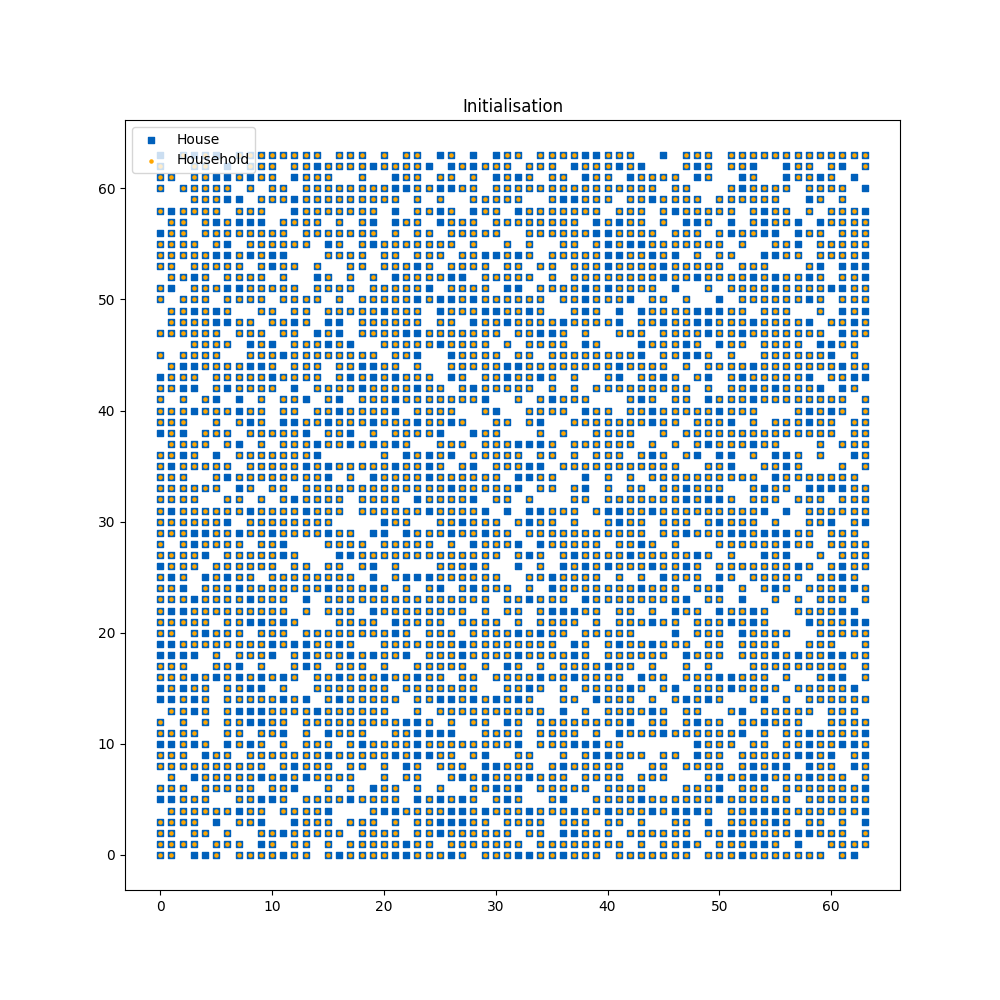

In [11]:
plt.figure(figsize=(10, 10))
plt.title("Initialisation")
plt.scatter(h_dict["x"], h_dict["y"], s=20, marker="s", color="#0060BB", label="House")
plt.scatter(hh_dict["x"], hh_dict["y"], s=5, color="#FFA600", label="Household")
plt.legend()
plt.show()
# plt.close()


In [12]:
plt.close()